In [2]:
import numpy as np 
print(np.random.default_rng().integers(0, 2**31))


1355007499


In [15]:
import numpy as np 
import matplotlib.pyplot as plt

SEED = 629064958
rng = np.random.default_rng(SEED)
rng_step4 = rng.spawn(1)[0]

print("Part 1 - Rayleigh Moments")

N_rayleigh = 1000000
rayleigh_samples = rng_step4.rayleigh(scale = 1.0, size = N_rayleigh) 

# first four moments
true_moments = { 
    1: np.sqrt(np.pi / 2.0 ),
    2: 2.0,
    3: 3 * np.sqrt(np.pi / 2.0),
    4: 8.0 
}
for k in [1, 2, 3, 4]:
    sample_kth = rayleigh_samples ** k
    estimate_moment = np.mean(sample_kth)
    true_moment = true_moments[k]

    #units in standard error
std_error = np.std(sample_kth, ddof = 1) / np.sqrt(N_rayleigh)

z_score = np.abs(estimate_moment - true_moment) / std_error 

print(f"Moment {k}: Estimated = {estimate_moment:.4f} | True = {true_moment:.4f} | Diff = {z_score:.4f} std errors")  

pareto_samples = rng_step4.pareto(a=1.5, size = 1000000) + 1

cp = [1000, 10000, 100000, 1000000] 

print(f"{"N":>10} | {"Sample Mean (True = 3)" :>25} | {"Sample Variance (True = Inf)" :>30}") 
print("-" * 72)

print("Part 2 - Pareto Distribution")

# pareto samples 
pareto_samples = rng_step4.pareto(a=1.5, size = 1000000) + 1
N_pareto = [1000, 10000, 100000, 1000000]

print(f"{'N':>10} | {'Sample Mean (True = 3.0)':>25} | {'Sample Variance (True = INF)':>30}") 

print("_" * 72) 

for n in N_pareto: 
    subset = pareto_samples[:n]
    mean_val = np.mean(subset)
    variance_val = np.var(subset, ddof=1)

print(f"{n:>10} | {mean_val:>25.4f} | {variance_val:>30.4f}")


Part 1 - Rayleigh Moments
Moment 4: Estimated = 7.9895 | True = 8.0000 | Diff = 0.5899 std errors
         N |    Sample Mean (True = 3) |   Sample Variance (True = Inf)
------------------------------------------------------------------------
Part 2 - Pareto Distribution
         N |  Sample Mean (True = 3.0) |   Sample Variance (True = INF)
________________________________________________________________________
   1000000 |                    3.0004 |                       741.8814


Figure 4


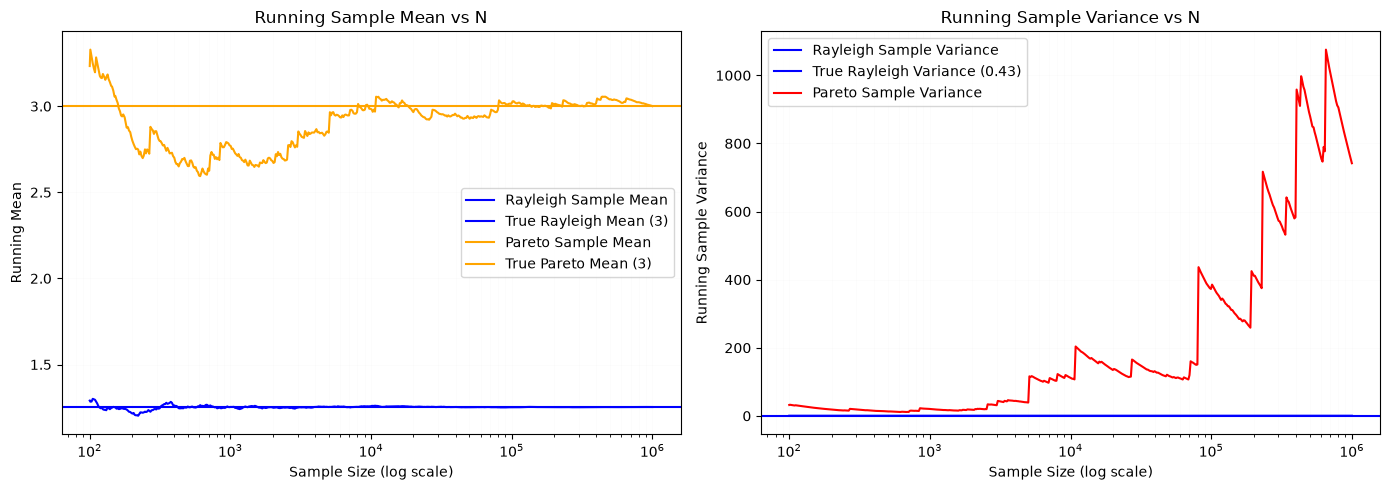

In [27]:
print("Figure 4")

indices = np.arange(1, 1000001) 

pareto_cumsum = np.cumsum (pareto_samples)
pareto_running_mean = pareto_cumsum / indices
pareto_cumsum_square = np.cumsum(pareto_samples ** 2) 
pareto_running_variance = (pareto_cumsum_square - indices * (pareto_running_mean ** 2)) / np.maximum(indices - 1, 1)

rayleigh_cumsum = np.cumsum (rayleigh_samples)
rayleigh_running_mean = rayleigh_cumsum / indices
rayleigh_cumsum_square = np.cumsum(rayleigh_samples ** 2) 
rayleigh_running_variance = (rayleigh_cumsum_square - indices * (rayleigh_running_mean ** 2)) / np.maximum(indices - 1, 1)

figure_4 = np.unique(np.logspace(2, 6, num=500).astype(int)) - 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 5))

ax1.plot(figure_4 + 1, rayleigh_running_mean[figure_4], label = "Rayleigh Sample Mean", color ="blue")
ax1.axhline(true_moments[1], color ="blue" , label = "True Rayleigh Mean (3)")

ax1.plot(figure_4 + 1, pareto_running_mean[figure_4], label = "Pareto Sample Mean", color ="orange")
ax1.axhline(3.0, color ="orange" , label = "True Pareto Mean (3)") 

ax1.set_xscale("log")
ax1.set_xlabel("Sample Size (log scale)")
ax1.set_ylabel("Running Mean")
ax1.set_title("Running Sample Mean vs N")
ax1.legend()
ax1.grid(True, which = "both", alpha = .03) 

true_rayleigh_variance = 2 - np.pi / 2
ax2.plot(figure_4 + 1, rayleigh_running_variance[figure_4], label = "Rayleigh Sample Variance", color = "blue")
ax2.axhline(true_rayleigh_variance, color = "blue", label = f"True Rayleigh Variance ({true_rayleigh_variance:.2f})")

ax2.plot(figure_4 +1, pareto_running_variance[figure_4], label = "Pareto Sample Variance", color = "red")

ax2.set_xscale("log")
ax2.set_xlabel("Sample Size (log scale)")
ax2.set_ylabel("Running Sample Variance")
ax2.set_title("Running Sample Variance vs N")
ax2.legend()
ax2.grid(True, which = "both", alpha = .03) 

plt.tight_layout()
plt.show()